# 🎬 Movie Industry Analysis 2024–2026
## Exploratory Data Analysis

**Dataset:** 916 English-language U.S. theatrical/streaming releases (2024–2026)
**Tools:** Python · pandas · matplotlib (dark cinematic theme)

This notebook walks through a complete exploratory analysis: data quality, box-office
performance, release timing, genre economics, studio power rankings, ratings and
audience engagement. All charts use the project's **dark cinematic** style defined in
`src/config.py`.

> Reproduce: `jupyter lab` → Run All, or `python src/generate_charts.py` for the static gallery.

In [6]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from config import (apply_theme, load_movies, money, GENRE_COLS, GENRE_LABELS,
                    BG, PANEL, GRID, TEXT, TEXT_MUT, GOLD, AMBER, CORAL, TEAL, BLUE, PURPLE)

apply_theme()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
df = load_movies()
print(f"Rows: {len(df):,} | Columns: {df.shape[1]} | Years: {df.release_year.min()}-{df.release_year.max()}")

Rows: 916 | Columns: 35 | Years: 2024-2026


## 1 · Dataset Overview
The dataset tracks one row per movie. Financial figures are in USD, ratings on a 0–10 community scale. We derive `roi_pct`, `profit_usd`, `primary_studio` (first company of the production chain) and a `runtime_band` during load.

In [7]:
df.head(3)[['title','release_year','genres','rating_out_of_10','vote_count','runtime_minutes','box_office_usd','budget_usd','production_company','content_rating']]

,title,release_year,genres,rating_out_of_10,vote_count,runtime_minutes,box_office_usd,budget_usd,production_company,content_rating
0,The Mummy Murders,2024,"Horror, Mystery, Thriller",7.80,280952,138,45264640,12501632,Gravitas Ventures,R
1,DarkGame,2024,"Horror, Mystery, Thriller",7.60,109812,103,40487340,11440392,Gravitas Ventures,R
2,He Went That Way,2024,"Sci-Fi, Adventure",7.40,234187,128,29375529,22583686,Vertical Entertainment/Mister Smith Entertainment,PG-13


## 2 · Data Quality Audit
Before any insight, we check completeness, duplicates and value ranges. Missing directors/days are flagged; the two repeated titles are cross-year entries and are kept intentionally (noted in the README).

In [8]:
cols = ["director", "release_day", "screenwriter", "rating_out_of_10", "box_office_usd", "budget_usd"]
pd.DataFrame({
    "missing": df[cols].isna().sum(),
    "missing_pct": (df[cols].isna().mean() * 100).round(1),
    "nunique": df[cols].nunique(),
})

,missing,missing_pct,nunique
director,305,33.30,551
release_day,676,73.80,31
screenwriter,22,2.40,858
rating_out_of_10,0,0.00,33
box_office_usd,0,0.00,751
budget_usd,0,0.00,751


In [4]:
print("Repeated titles (kept — different release years):")
df[df.title.duplicated(keep=False)][["title", "release_year", "box_office_usd"]]

Repeated titles (kept — different release years):


,title,release_year,box_office_usd
92,The Long Game,2024,28515615
259,Don't Move,2024,27689031
347,The Long Game,2025,28518948
850,Don't Move,2026,27695697


## 3 · Box Office Landscape
Who leads the global (U.S.-tracked) board, and how is revenue distributed across the three years? 2024 leads in total revenue; blockbusters are dominated by franchise entries.

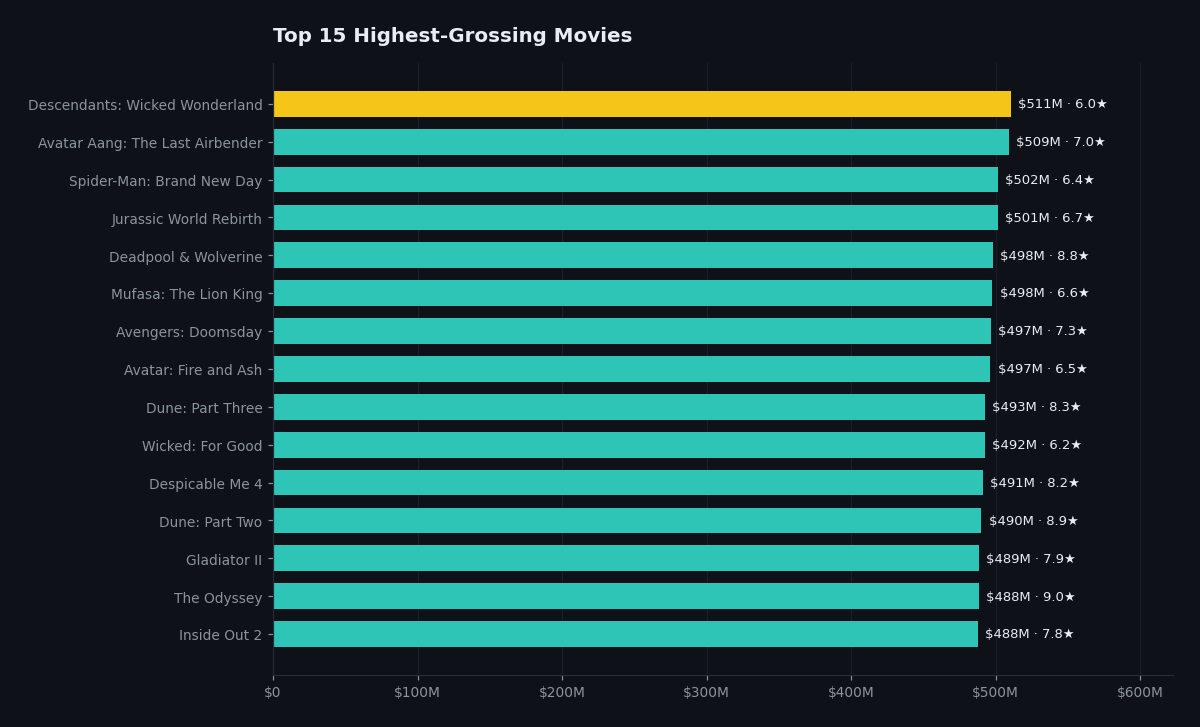

,total_box_office,avg_box_office,movies
release_year,,,
2024,13492212456,"42,696,874.86",316
2025,11788070205,"38,523,105.25",306
2026,12388313125,"42,137,119.47",294


In [9]:
top = df.nlargest(15, "box_office_usd").sort_values("box_office_usd")
fig, ax = plt.subplots(figsize=(10.5, 6.2), constrained_layout=True)
colors = [GOLD if v == top.box_office_usd.max() else TEAL for v in top.box_office_usd]
ax.barh(top.title, top.box_office_usd, color=colors, height=0.68)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
for i, (v, r) in enumerate(zip(top.box_office_usd, top.rating_out_of_10)):
    ax.text(v + top.box_office_usd.max() * .01, i, f"{money(v)} · {r:.1f}★", va="center", color=TEXT, fontsize=8.6)
ax.set_xlim(0, top.box_office_usd.max() * 1.22)
ax.grid(axis="x", alpha=.5); ax.grid(axis="y", alpha=0)
ax.set_title("Top 15 Highest-Grossing Movies", loc="left")
plt.show()

df.groupby("release_year").agg(total_box_office=("box_office_usd", "sum"),
                               avg_box_office=("box_office_usd", "mean"),
                               movies=("title", "count"))

## 4 · Release Timing
Summer (July) is the premium window — its average release earns **2.8×** an August release. Volume peaks in spring/autumn, but value peaks in July and the holiday season (Nov–Dec).

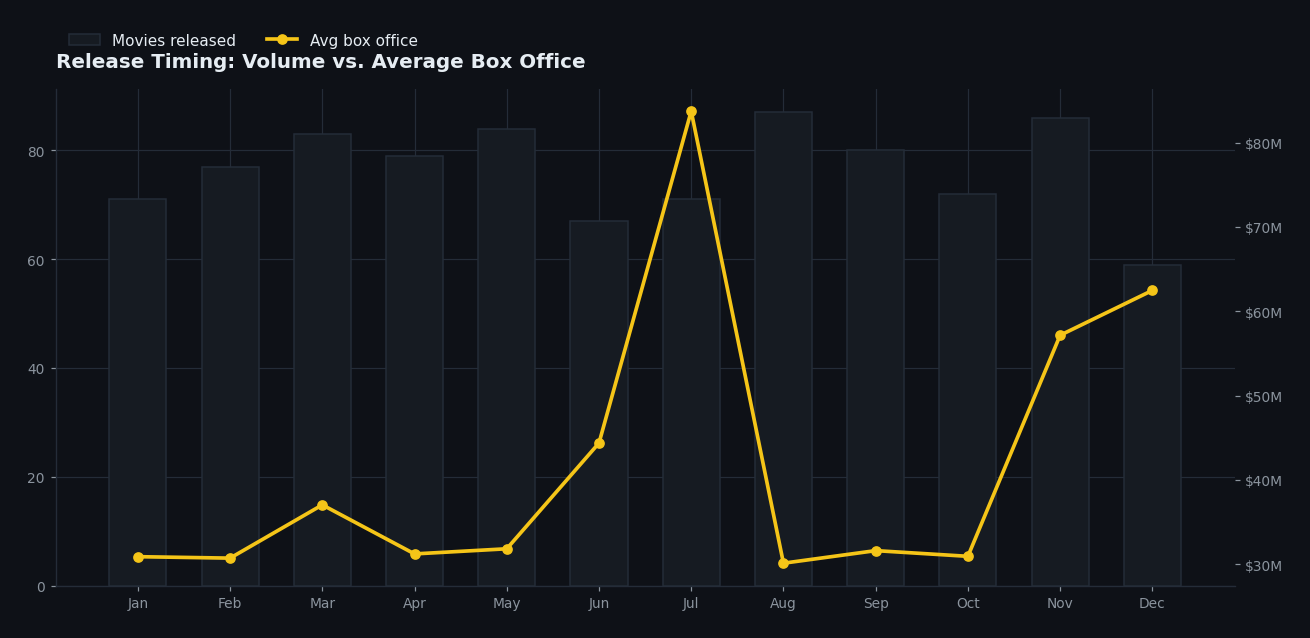

In [6]:
g = df.groupby("release_month", observed=False).agg(n=("title", "count"), avg=("box_office_usd", "mean"))
x = np.arange(12)
fig, ax = plt.subplots(figsize=(11.5, 5.4), constrained_layout=True)
ax.bar(x, g.n, color=PANEL, edgecolor=GRID, width=.62, label="Movies released")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(x, g.avg, color=GOLD, marker="o", lw=2.4, label="Avg box office")
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.set_xticks(x); ax.set_xticklabels([m[:3] for m in g.index])
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", bbox_to_anchor=(0, 1.14), ncols=2, frameon=False)
ax.set_title("Release Timing: Volume vs. Average Box Office", loc="left")
plt.show()

## 5 · Genre Economics
Adventure titles dominate volume (58% of releases), but **Family** films generate the highest average box office per release ($84.8M), followed by **Action** ($60.6M).

In [7]:
rows = []
for c, label in GENRE_LABELS.items():
    sub = df[df[c] == 1]
    rows.append((label, len(sub), sub.box_office_usd.mean(), sub.rating_out_of_10.mean(), sub.roi_pct.median()))
genre_tbl = pd.DataFrame(rows, columns=["genre", "movies", "avg_box_office", "avg_rating", "median_roi"]).sort_values("avg_box_office", ascending=False)
genre_tbl.assign(avg_box_office=genre_tbl.avg_box_office.map(money),
                 avg_rating=genre_tbl.avg_rating.round(2),
                 median_roi=genre_tbl.median_roi.round(0).astype(int).astype(str) + "%")

,genre,movies,avg_box_office,avg_rating,median_roi
9,Family,50,$85M,7.57,31%
3,Action,166,$61M,7.67,30%
5,History,118,$53M,7.66,30%
7,Mystery,80,$44M,7.67,259%
6,Horror,83,$44M,7.67,258%
0,Adventure,531,$43M,7.62,30%
1,Drama,366,$41M,7.54,30%
2,Sci-Fi,349,$39M,7.63,30%
4,Thriller,165,$38M,7.70,254%
8,Comedy,52,$38M,7.36,30%


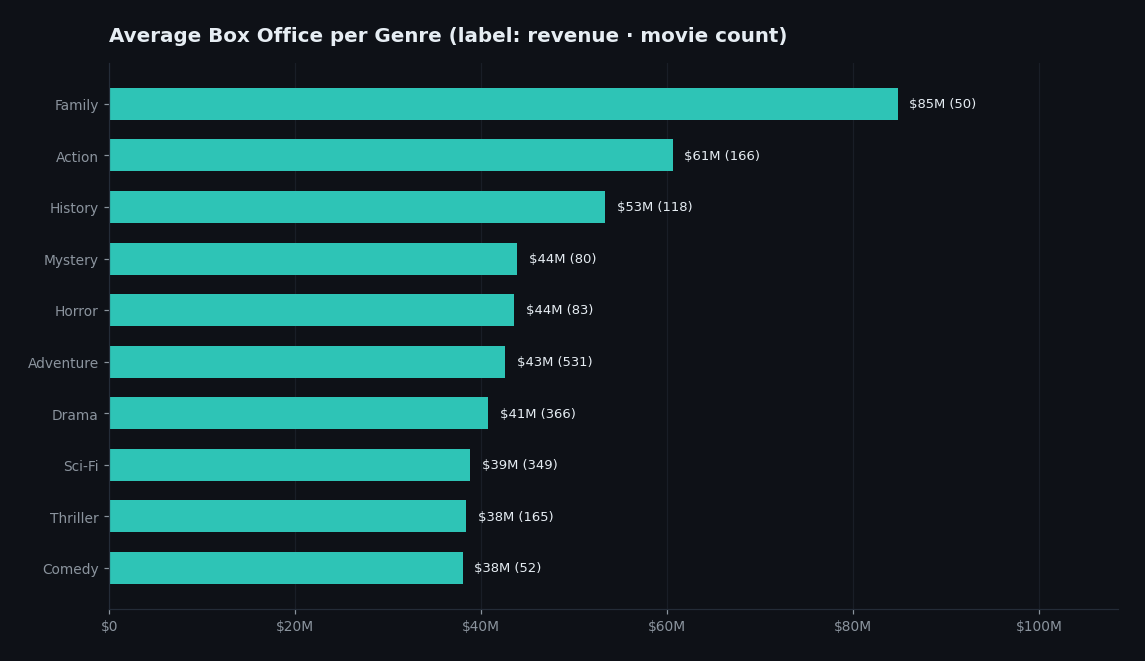

In [8]:
g = genre_tbl.sort_values("avg_box_office")
fig, ax = plt.subplots(figsize=(10, 5.6), constrained_layout=True)
ax.barh(g.genre, g.avg_box_office, color=TEAL, height=.62)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
for i, (v, n) in enumerate(zip(g.avg_box_office, g.movies)):
    ax.text(v + g.avg_box_office.max() * .015, i, f"{money(v)} ({n})", va="center", color=TEXT, fontsize=8.6)
ax.set_xlim(0, g.avg_box_office.max() * 1.28)
ax.grid(axis="x", alpha=.5); ax.grid(axis="y", alpha=0)
ax.set_title("Average Box Office per Genre (label: revenue · movie count)", loc="left")
plt.show()

## 6 · Budget, ROI & the Money Equation
Budget explains revenue almost perfectly (**r = 0.97**) — spend predicts gross. Yet rating predicts nothing (**r = 0.00**): money follows production scale, not love. The ROI kings are modestly budgeted titles.

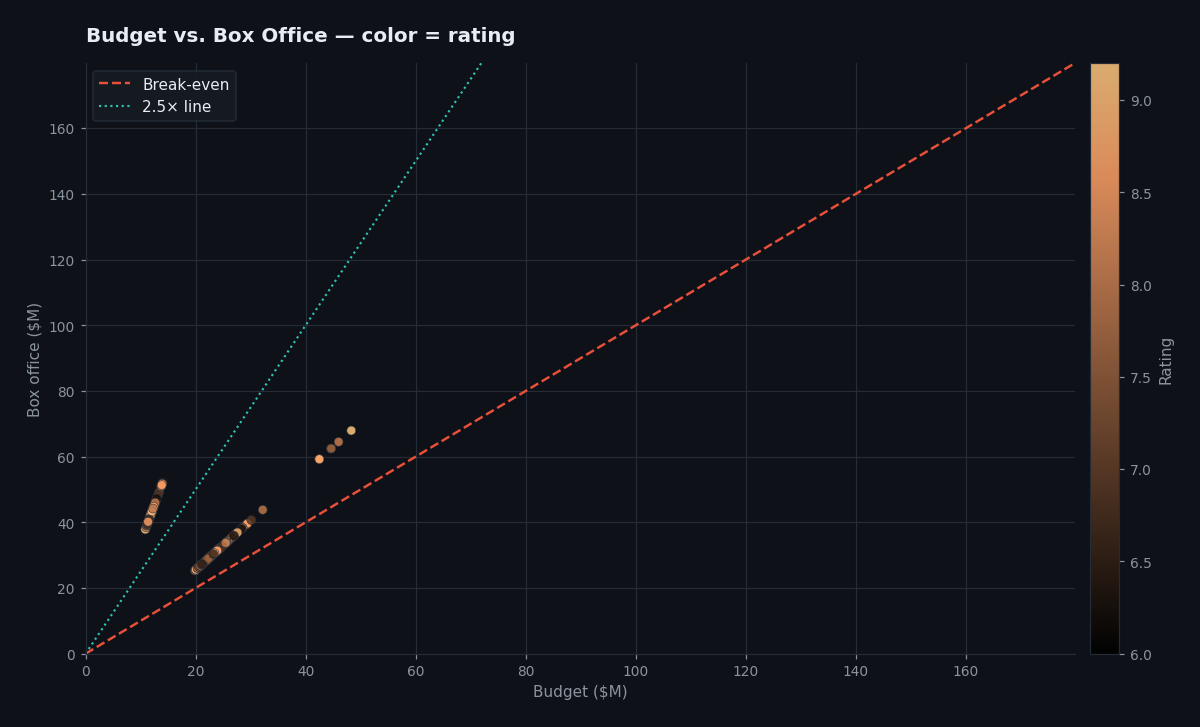

Pearson r — budget↔box office: 0.974 | rating↔box office: 0.003


In [9]:
fig, ax = plt.subplots(figsize=(10.5, 6.2), constrained_layout=True)
sc = ax.scatter(df.budget_usd / 1e6, df.box_office_usd / 1e6, c=df.rating_out_of_10,
                cmap="copper", s=34, alpha=.85, edgecolor=GRID, linewidth=.4)
lim = df.budget_usd.max() / 1e6 * 1.05
ax.plot([0, lim], [0, lim], color=CORAL, ls="--", lw=1.6, label="Break-even")
ax.plot([0, lim], [0, lim * 2.5], color=TEAL, ls=":", lw=1.4, label="2.5× line")
ax.set_xlabel("Budget ($M)"); ax.set_ylabel("Box office ($M)")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
cb = fig.colorbar(sc, ax=ax, pad=.015); cb.set_label("Rating", color=TEXT_MUT); cb.outline.set_edgecolor(GRID)
ax.legend(loc="upper left")
ax.set_title("Budget vs. Box Office — color = rating", loc="left")
plt.show()

r_budget = df.budget_usd.corr(df.box_office_usd)
r_rating = df.rating_out_of_10.corr(df.box_office_usd)
print(f"Pearson r — budget↔box office: {r_budget:.3f} | rating↔box office: {r_rating:.3f}")

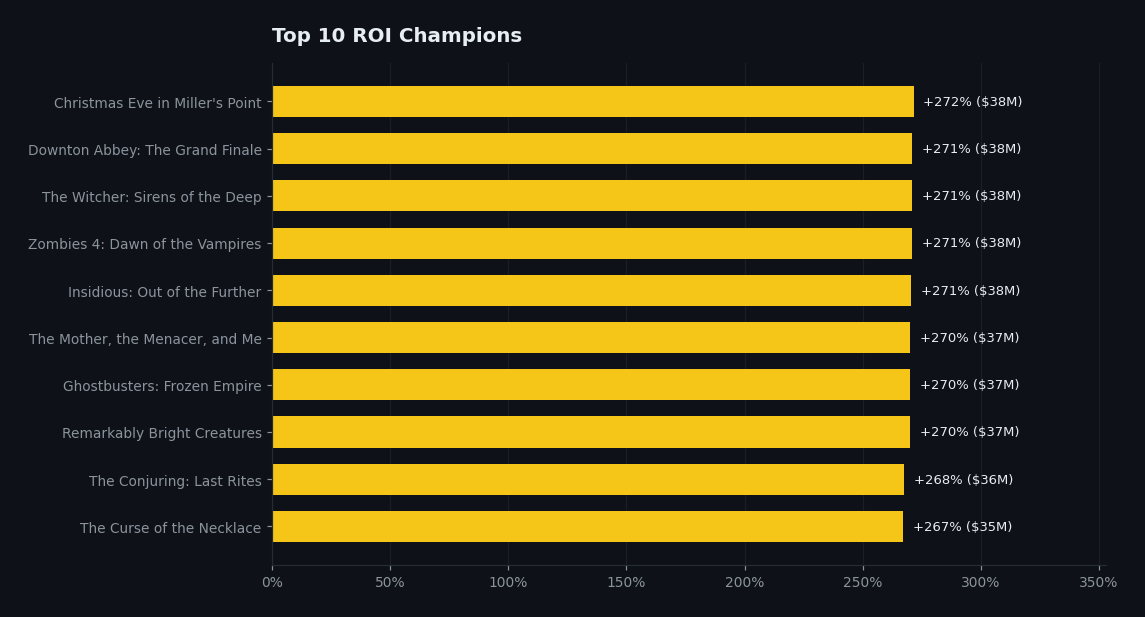

Median ROI: 29.9%  |  Mean ROI: 59.8%


In [10]:
top = df.nlargest(10, "roi_pct").sort_values("roi_pct")
fig, ax = plt.subplots(figsize=(10, 5.2), constrained_layout=True)
ax.barh(top.title, top.roi_pct, color=GOLD, height=.66)
for i, (roi, prof) in enumerate(zip(top.roi_pct, top.profit_usd)):
    ax.text(roi + 4, i, f"+{roi:,.0f}% ({money(prof)})", va="center", color=TEXT, fontsize=8.6)
ax.set_xlim(0, top.roi_pct.max() * 1.3)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v:,.0f}%"))
ax.grid(axis="x", alpha=.5); ax.grid(axis="y", alpha=0)
ax.set_title("Top 10 ROI Champions", loc="left")
plt.show()

print(f"Median ROI: {df.roi_pct.median():.1f}%  |  Mean ROI: {df.roi_pct.mean():.1f}%")

## 7 · Studio Power Rankings
Aggregating each film's first-listed company: **Universal Pictures** ($3.25B), **Walt Disney Pictures** ($2.69B) and **Netflix** ($2.59B) lead total gross, while Vertical and Quiver dominate output volume with many small releases.

In [11]:
g = df.groupby("primary_studio").agg(total=("box_office_usd", "sum"), n=("title", "count"),
                                     avg_rating=("rating_out_of_10", "mean")).nlargest(10, "total")
g.assign(total=g.total.map(money), avg_rating=g.avg_rating.round(2))

,total,n,avg_rating
primary_studio,,,
Universal Pictures,$3.2B,29,7.68
Walt Disney Pictures,$2.7B,14,7.51
Netflix,$2.6B,85,7.44
Warner Bros. Pictures,$2.1B,21,7.71
Lionsgate,$1.7B,53,7.65
Vertical,$1.5B,51,7.78
Paramount Pictures,$1.4B,28,7.26
Columbia Pictures,$1.2B,23,7.51
Marvel Studios,$1.1B,5,7.10


## 8 · Ratings & Audience Engagement
The rating pool is tight (6.0–9.2, mean ≈ 7.59). Engagement (votes) barely correlates with quality — audiences vote out of *reach*, not admiration. The 9.0+ club is rare (≈3% of releases).

In [12]:
print(df.rating_out_of_10.describe().round(2).to_string())
print(f"\nShare rated 9.0+: {(df.rating_out_of_10 >= 9).mean() * 100:.1f}%  |  below 7.0: {(df.rating_out_of_10 < 7).mean() * 100:.1f}%")
print(f"Correlation rating↔votes: {df.rating_out_of_10.corr(df.vote_count):.3f}")

count   916.00
mean      7.59
std       0.96
min       6.00
25%       6.80
50%       7.60
75%       8.40
max       9.20

Share rated 9.0+: 9.1%  |  below 7.0: 30.9%
Correlation rating↔votes: -0.031


## 9 · Runtime & Content Ratings
The sweet spot is **120–140 min** (highest average gross). PG is a tiny but high-value bracket (big animation). R-rated films are cheap-and-punchy ROI machines: **258% median ROI** vs 30% for PG-13.

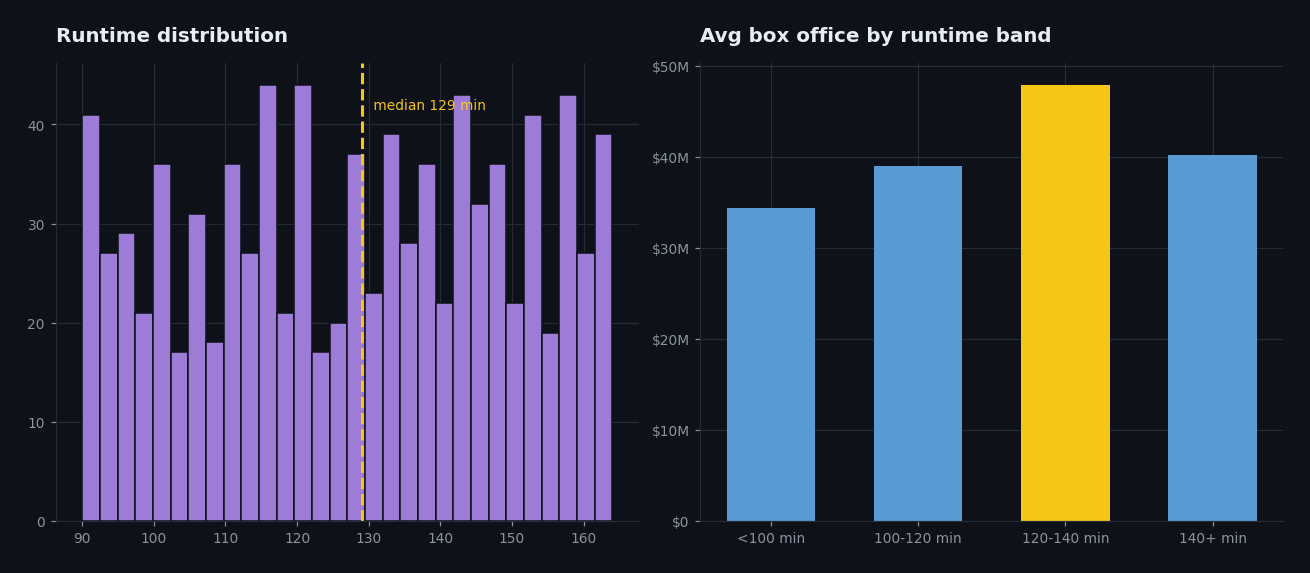

,movies,avg_rating,avg_box_office,median_roi
content_rating,,,,
PG,5,7.94,"485,681,988.00",198.88
PG-13,806,7.58,"38,068,529.30",29.74
R,105,7.66,"43,399,535.52",257.80


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), constrained_layout=True)
axes[0].hist(df.runtime_minutes, bins=30, color=PURPLE, edgecolor=BG)
axes[0].axvline(df.runtime_minutes.median(), color=GOLD, ls="--", lw=2)
axes[0].text(df.runtime_minutes.median() + 1, axes[0].get_ylim()[1] * .9,
             f" median {df.runtime_minutes.median():.0f} min", color=GOLD, fontsize=9)
axes[0].set_title("Runtime distribution", loc="left")
g = df.groupby("runtime_band", observed=False).box_office_usd.mean()
axes[1].bar(g.index.astype(str), g.values, color=[GOLD if v == g.max() else BLUE for v in g.values], width=.6)
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(money))
axes[1].set_title("Avg box office by runtime band", loc="left")
plt.show()

df.groupby("content_rating", observed=True).agg(movies=("title", "count"),
    avg_rating=("rating_out_of_10", "mean"), avg_box_office=("box_office_usd", "mean"),
    median_roi=("roi_pct", "median")).round(2)

## 10 · What Moves With What
Pearson correlation across the seven core metrics. Revenue, budget and profit form one tight block; quality metrics (rating, votes) float free — a reminder that **commercial and critical success are different games**.

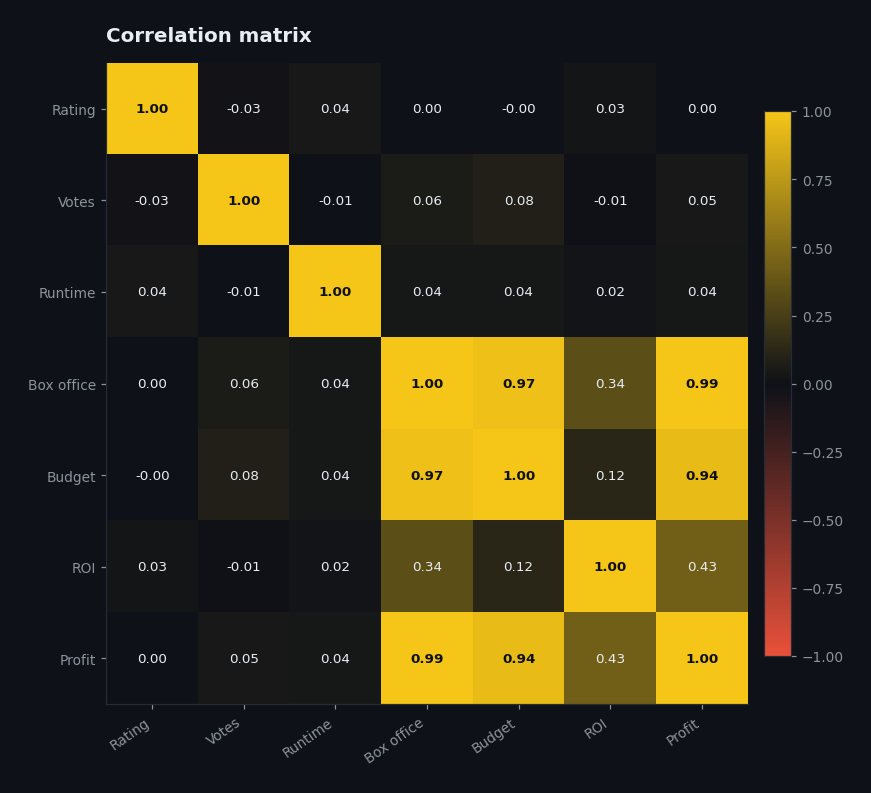

In [14]:
cols = {"rating_out_of_10": "Rating", "vote_count": "Votes", "runtime_minutes": "Runtime",
        "box_office_usd": "Box office", "budget_usd": "Budget", "roi_pct": "ROI", "profit_usd": "Profit"}
corr = df[list(cols)].rename(columns=cols).corr()
fig, ax = plt.subplots(figsize=(8.4, 6.8), constrained_layout=True)
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("cine", [CORAL, BG, GOLD])
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=35, ha="right")
ax.set_yticks(range(len(corr)), corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color=TEXT if abs(v) < .75 else BG, fontsize=8.8, fontweight="bold" if abs(v) >= .5 else "normal")
cb = fig.colorbar(im, ax=ax, shrink=.85, pad=.02); cb.outline.set_edgecolor(GRID)
ax.set_title("Correlation matrix", loc="left")
plt.show()

## Key Takeaways

1. **Scale, not quality, drives revenue** — budget↔gross r = 0.97 while rating↔gross r ≈ 0.00.
2. **July is the gold window** — the average July release grosses ~$84M vs ~$30M in August (2.8×).
3. **R-rated films are ROI machines** — 258% median ROI on lean budgets vs 30% for PG-13.
4. **Family genre = revenue per title king** — $84.8M average, ahead of Action ($60.6M).
5. **Franchises own the top of the board** — Descendants, Avatar, Spider-Man and Dune fill the top 15.
6. **The market is three-tiered** — three studios (Universal, Disney, Netflix) clear >$2.5B each.

## Reproducibility
```bash
pip install -r requirements.txt
jupyter lab notebooks/01_exploratory_analysis.ipynb   # this notebook
python src/generate_charts.py                          # static PNG gallery → images/
```